# 🧪 AICE Associate 모의고사 1 · 배달 도착시간 예측 (회귀) — 정답 및 해설

> 난이도 ★★☆ (공식 샘플 문항 수준) · 14문항 · 100점 · 합격 80점 · 제한시간 90분

이 노트북은 **정답 코드 + 해설**입니다. 먼저 문제 노트북을 직접 풀고, 채점한 뒤에 보세요.
맨 아래 채점 셀을 실행하면 100점이 나와야 정상입니다.

---

## 시나리오
배달 플랫폼 **'AI배달'** 은 고객에게 정확한 도착 예정 시간을 알려 주려고 합니다.
**주문 데이터(json)** 와 **라이더 데이터(csv)** 를 합쳐서 **배달 소요시간 `Delivery_Time`(분)** 을 예측하는 모델을 만드세요.

흐름: `import → 읽기·병합 → 시각화 → 이상치 → 결측치 → 컬럼 삭제 → 원-핫 → 분할 → ML 학습 → ML 평가 → DL 학습 → DL 평가`

In [1]:
# [준비 셀] 문제가 아닙니다. 그대로 실행하세요.
import os, warnings
os.environ['OMP_NUM_THREADS'] = '1'         # macOS: XGBoost 와 PyTorch 를 한 노트북에서 쓸 때 멈춤 방지 (맨 처음 실행)
warnings.filterwarnings('ignore')            # 불필요한 경고 숨기기
import sys
sys.path.insert(0, '..')                    # 채점기(aice_check.py) 위치
DATA_DIR = '../../data/'

## 데이터 설명
**delivery_orders.json** (주문)

| 컬럼 | 설명 | 컬럼 | 설명 |
|---|---|---|---|
| order_id | 주문 ID | Food_Type | 음식 종류 |
| rider_id | 라이더 ID (병합 키) | Items | 주문 수량 |
| Order_Time | 주문 시각 | Hour | 주문 시(0~23) |
| Arrive_Time | 도착 시각 | Distance_km | 배달 거리(km) |
| Region | 배달 지역 (`'-'` = 미기재) | Prep_Time | 조리 시간(분) |
| Weather | 날씨 | Speed_Per_Hour | 평균 주행 속도(km/h) |
| **Delivery_Time** | **배달 소요시간(분) ← 예측 대상** | | |

**delivery_riders.csv** (라이더): `rider_id`, `Rider_Age`(나이), `Vehicle`(이동수단), `Experience_Months`(경력 개월), `Rider_Rating`(평점)

---
### 문항 1 &nbsp;<small>(4점)</small> &nbsp; 라이브러리 불러오기 ①

**pandas** 를 **`pd`** 로, **numpy** 를 **`np`** 로 import 하세요.

In [2]:
import pandas as pd
import numpy as np

> **해설**
>
> 시험 1~2번은 거의 항상 import 문제입니다. 별칭(alias)이 **정확히** 문제와 같아야 합니다.
> `import pandas` 만 하고 `pd` 를 안 만들면 이후 모든 `pd.` 코드가 NameError 가 납니다.

---
### 문항 2 &nbsp;<small>(4점)</small> &nbsp; 라이브러리 불러오기 ②

**seaborn** 을 **`sns`** 로, **matplotlib.pyplot** 을 **`plt`** 로 import 하세요.

In [3]:
import seaborn as sns
import matplotlib.pyplot as plt

> **해설**
>
> `import matplotlib as plt` 는 **틀립니다**. 그래프 함수는 `matplotlib.pyplot` 안에 있습니다.

---
### 문항 3 &nbsp;<small>(7점)</small> &nbsp; 데이터 읽기 + 병합

- `DATA_DIR + 'delivery_orders.json'` 을 읽어 **`df_orders`** 에 저장하세요.
- `DATA_DIR + 'delivery_riders.csv'` 를 읽어 **`df_riders`** 에 저장하세요.
- 두 데이터를 **`rider_id`** 기준 **inner** 방식으로 병합하여 **`df`** 에 저장하세요.

In [4]:
df_orders = pd.read_json(DATA_DIR + 'delivery_orders.json')
df_riders = pd.read_csv(DATA_DIR + 'delivery_riders.csv')
df = pd.merge(df_orders, df_riders, on='rider_id', how='inner')
print(df_orders.shape, df_riders.shape, df.shape)

(6000, 13) (300, 5) (5953, 17)


> **해설**
>
> - json 은 `pd.read_json`, csv 는 `pd.read_csv`. 확장자를 보고 함수를 고르세요.
> - `pd.merge(왼쪽, 오른쪽, on='키', how='inner')` — `how` 기본값이 `'inner'` 라서 생략해도 정답입니다.
> - `how='left'` 로 하면 라이더 정보가 없는 주문(퇴사 라이더 47건)이 NaN 으로 남아 **틀립니다**. 행 수(6000 → 5953)가 줄어든 이유가 바로 inner 병합입니다.
> - `df_orders.merge(df_riders, on='rider_id')` 처럼 써도 같은 결과입니다.

---
### 문항 4 &nbsp;<small>(7점)</small> &nbsp; 범주 분포 확인 + 잘못된 값 제거

- `Region` 컬럼의 값 분포를 seaborn **countplot** 으로 그리세요.
- `Region` 값이 **`'-'`** 인 행을 삭제하고, 결과를 다시 **`df`** 에 저장하세요.

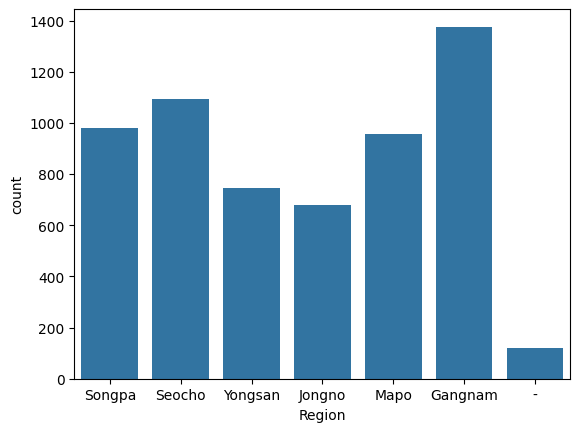

(5834, 17)


In [5]:
sns.countplot(data=df, x='Region')
plt.show()

df = df[df['Region'] != '-']
print(df.shape)

> **해설**
>
> - 그래프에 `-` 막대가 보이죠? 지역이 기록되지 않은 데이터입니다.
> - 불리언 인덱싱 `df[조건]` 으로 **남길 행**을 고릅니다. `'-'` 가 **아닌** 행을 남기면 됩니다.
> - 자주 틀리는 포인트: `df[df['Region'] != '-']` 만 실행하고 **`df =` 로 다시 저장하지 않는 것**. 화면에만 출력되고 df 는 그대로입니다.
> - 다른 정답: `df = df.drop(df[df['Region'] == '-'].index)`

---
### 문항 5 &nbsp;<small>(6점)</small> &nbsp; 두 변수 관계 시각화

`Distance_km`(x축)와 `Delivery_Time`(y축)의 관계를 seaborn **jointplot** 으로 그리고, 반환값을 **`g`** 에 저장하세요.

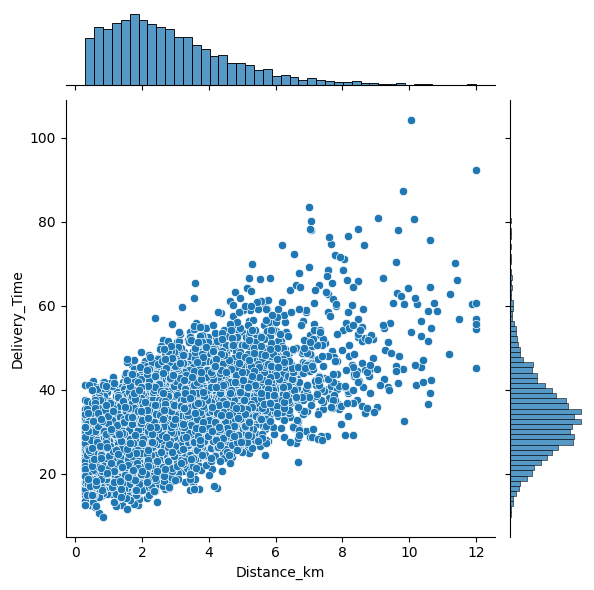

In [6]:
g = sns.jointplot(data=df, x='Distance_km', y='Delivery_Time')
plt.show()

> **해설**
>
> - 거리가 멀수록 배달 시간이 길어지는 **양의 상관관계**가 보입니다.
> - `jointplot` 은 가운데 산점도 + 위/오른쪽에 각 변수의 분포(히스토그램)를 같이 보여 줍니다.
> - 시험에서는 "그래프를 보고 알 수 있는 것을 고르라" 는 식으로 해석을 묻기도 합니다. x/y 를 바꾸지 않도록 주의!

---
### 문항 6 &nbsp;<small>(7점)</small> &nbsp; 이상치 제거

`Speed_Per_Hour` 의 분포를 확인하고(describe 또는 boxplot), 시속 **150 이상**인 데이터는 GPS 오류로 보고 **제거**하세요.
결과는 **`df_temp`** 에 저장하세요.

count    5834.000000
mean       27.458742
std        62.280250
min         6.000000
25%        17.300000
50%        22.700000
75%        26.300000
max       997.500000
Name: Speed_Per_Hour, dtype: float64


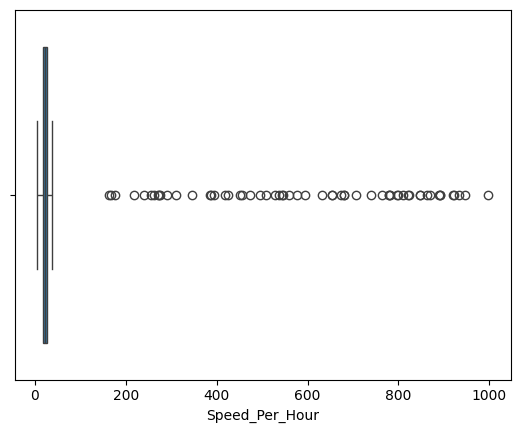

(5834, 17) -> (5775, 17)


In [7]:
print(df['Speed_Per_Hour'].describe())
sns.boxplot(x=df['Speed_Per_Hour'])
plt.show()

df_temp = df[df['Speed_Per_Hour'] < 150]
print(df.shape, '->', df_temp.shape)

> **해설**
>
> - describe 의 `max` 가 999 근처, 75% 값은 30 정도 → 오토바이로 시속 999km 는 불가능하니 오류입니다.
> - **"150 이상 제거" = "150 미만만 남김"** → `< 150`. `<= 150` 으로 쓰면 경계값을 잘못 다루게 됩니다. 시험에서 "이상/이하/초과/미만" 은 꼭 다시 읽으세요.
> - 결과를 `df` 가 아니라 **새 변수 `df_temp`** 에 저장해야 합니다.

---
### 문항 7 &nbsp;<small>(7점)</small> &nbsp; 결측치 처리

`df_temp` 의 컬럼별 결측치 개수를 확인하고, 결측치가 있는 **행을 삭제**하여 **`df_na`** 에 저장하세요.

In [8]:
print(df_temp.isna().sum())
df_na = df_temp.dropna(axis=0)
print(df_na.isna().sum().sum(), df_na.shape)

order_id               0
rider_id               0
Order_Time             0
Arrive_Time            0
Region                 0
Weather              106
Food_Type              0
Items                 69
Hour                   0
Distance_km            0
Prep_Time              0
Speed_Per_Hour         0
Delivery_Time          0
Rider_Age              0
Vehicle                0
Experience_Months      0
Rider_Rating         193
dtype: int64
0 (5412, 17)


> **해설**
>
> - `isna().sum()` → 컬럼별 결측 개수. `Weather`, `Items`, `Rider_Rating` 에 결측이 있습니다.
> - `dropna(axis=0)` 은 결측이 하나라도 있는 **행**을 지웁니다(`axis=0` 이 기본값).
> - `dropna(axis=1)` 로 쓰면 **컬럼**이 사라지니 주의하세요.
> - `df_temp.dropna(inplace=True)` 를 쓰면 반환값이 `None` 이라 `df_na = df_temp.dropna(inplace=True)` 는 **틀립니다**.

---
### 문항 8 &nbsp;<small>(7점)</small> &nbsp; 불필요한 컬럼 삭제

학습에 쓰지 않을 **`'order_id', 'rider_id', 'Order_Time', 'Arrive_Time'`** 컬럼을 삭제하여 **`df_del`** 에 저장하세요.

In [9]:
df_del = df_na.drop(['order_id', 'rider_id', 'Order_Time', 'Arrive_Time'], axis=1)
df_del.head()

,Region,Weather,Food_Type,Items,Hour,Distance_km,Prep_Time,Speed_Per_Hour,Delivery_Time,Rider_Age,Vehicle,Experience_Months,Rider_Rating
0,Songpa,Rainy,Pizza,2.0,15,2.14,24.0,22.2,34.3,23,Motorcycle,66,4.8
1,Seocho,Sunny,Chinese,5.0,11,2.14,24.4,27.3,34.9,49,Motorcycle,87,4.2
2,Seocho,Rainy,Korean,5.0,15,2.98,19.9,23.4,33.0,39,Motorcycle,66,4.5
3,Yongsan,Sunny,Burger,1.0,12,8.59,14.6,17.6,46.3,23,Car,79,4.1
4,Yongsan,Rainy,Korean,4.0,11,2.91,26.1,21.8,36.7,31,Motorcycle,41,4.5


> **해설**
>
> - ID 는 행마다 다른 값이라 패턴이 없고, `Arrive_Time` 은 **정답(도착 시각)을 그대로 담고 있어** 쓰면 반칙(데이터 누수)입니다.
> - 여러 컬럼은 **리스트**로 넘기고 `axis=1`(또는 `columns=[...]`).

---
### 문항 9 &nbsp;<small>(8점)</small> &nbsp; 원-핫 인코딩

`df_del` 의 **object 타입 컬럼 전부**를 pandas **get_dummies** 로 원-핫 인코딩하여 **`df_preset`** 에 저장하세요.

In [10]:
cols = df_del.select_dtypes('object').columns
print(list(cols))
df_preset = pd.get_dummies(data=df_del, columns=cols)
print(df_preset.shape)

['Region', 'Weather', 'Food_Type', 'Vehicle']
(5412, 28)


> **해설**
>
> - `select_dtypes('object')` 로 문자형 컬럼(Region, Weather, Food_Type, Vehicle)을 한 번에 찾습니다. 손으로 적다가 빠뜨리는 실수를 막아 줍니다.
> - 문제에 `drop_first` 지시가 없으면 기본값(False)으로 둡니다. 지시가 있으면 반드시 따르세요.
> - 새로 생긴 컬럼 타입은 **bool**(True/False) 입니다 → 13번 딥러닝에서 float 변환이 필요한 이유.

---
### 문항 10 &nbsp;<small>(8점)</small> &nbsp; 학습/검증 데이터 분리

`df_preset` 에서 **`Delivery_Time`** 을 y(타깃), 나머지를 X 로 하고, **test_size=0.2, random_state=42** 로 나누세요.
결과는 **`X_train, X_valid, y_train, y_valid`** 에 저장하세요.

In [11]:
from sklearn.model_selection import train_test_split

X = df_preset.drop('Delivery_Time', axis=1)
y = df_preset['Delivery_Time']
X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape, X_valid.shape, y_train.shape, y_valid.shape)

(4329, 27) (1083, 27) (4329,) (1083,)


> **해설**
>
> - 반환 순서 **X_train, X_test, y_train, y_test** 를 외워 두세요 (X 둘 → y 둘).
> - X 에서 타깃을 빼지 않으면 정답을 보고 정답을 맞히는 셈이 됩니다.
> - 회귀 문제(연속값)는 `stratify` 를 쓰지 않습니다. 분류 문제에서 지시가 있으면 `stratify=y`.

---
### 문항 11 &nbsp;<small>(8점)</small> &nbsp; 머신러닝 모델 학습

두 회귀 모델을 만들고 `X_train, y_train` 으로 학습하세요.
- **DecisionTreeRegressor**: **max_depth=5, min_samples_split=3, random_state=120** → **`dt`**
- **RandomForestRegressor**: **n_estimators=100, max_depth=12, random_state=42** → **`rf`**

In [12]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

dt = DecisionTreeRegressor(max_depth=5, min_samples_split=3, random_state=120)
dt.fit(X_train, y_train)

rf = RandomForestRegressor(n_estimators=100, max_depth=12, random_state=42)
rf.fit(X_train, y_train)

,n_estimators,100
,criterion,'squared_error'
,max_depth,12
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


> **해설**
>
> - 머신러닝은 **4줄 템플릿**: `import → 모델 = 클래스(파라미터) → 모델.fit(X, y) → 모델.predict(X)`.
> - 타깃이 숫자(분)이므로 **Regressor**. `DecisionTreeClassifier` 를 쓰면 0점입니다.
> - `DecisionTreeRegressor` 는 `sklearn.tree`, `RandomForestRegressor` 는 `sklearn.ensemble` 에 있습니다.

---
### 문항 12 &nbsp;<small>(8점)</small> &nbsp; 머신러닝 모델 평가

`X_valid` 로 예측하여 다음을 계산하세요.
- dt 의 MAE → **`dt_mae`**
- rf 의 MAE → **`rf_mae`**, RMSE → **`rf_rmse`**

In [13]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

dt_pred = dt.predict(X_valid)
rf_pred = rf.predict(X_valid)
dt_mae = mean_absolute_error(y_valid, dt_pred)
rf_mae = mean_absolute_error(y_valid, rf_pred)
rf_rmse = np.sqrt(mean_squared_error(y_valid, rf_pred))
print(f'DT MAE {dt_mae:.3f} | RF MAE {rf_mae:.3f} | RF RMSE {rf_rmse:.3f}')

DT MAE 2.766 | RF MAE 1.218 | RF RMSE 1.666


> **해설**
>
> - 평가 함수 인자 순서는 **(정답, 예측)**. MAE 는 순서를 바꿔도 값이 같지만, 습관을 들이세요.
> - RMSE = MSE 의 제곱근 → `np.sqrt(mean_squared_error(...))`. 버전에 따라 `root_mean_squared_error` 가 없을 수 있으니 이 방법이 가장 안전합니다.
> - 결과: 랜덤포레스트가 결정트리보다 오차가 작습니다 (나무 여러 그루의 평균).

---
### 문항 13 &nbsp;<small>(10점)</small> &nbsp; 딥러닝 모델 학습 (PyTorch)

아래 조건으로 PyTorch 회귀 모델을 만들고 학습하세요.
- 먼저 **`torch.manual_seed(42)`** 실행
- 텐서 변환 (모두 **float32**): X_train, X_valid → **`X_train_t`**, **`X_valid_t`** / y_train, y_valid → **`y_train_t`**, **`y_valid_t`** (모양 **(N, 1)**)
- **`train_loader`** = DataLoader(TensorDataset(X_train_t, y_train_t), **batch_size=32, shuffle=True**)
- **`model`** = nn.Sequential: **Linear(입력 컬럼 수, 64)** → **ReLU** → **Dropout(0.2)** → **Linear(64, 32)** → **ReLU** → **Linear(32, 1)**
- **`loss_fn`** = **nn.MSELoss()**, **`optimizer`** = **torch.optim.Adam(model.parameters(), lr=0.001)**
- **epochs=50** 동안 학습하면서, 매 epoch 마다 딕셔너리 **`history`** 의 **`'loss'`** (그 epoch 배치 손실의 평균)와 **`'val_loss'`** (eval 모드에서 검증 데이터 전체로 계산한 손실)에 값을 추가하세요.

In [14]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(42)

# get_dummies 로 생긴 bool 컬럼 때문에 astype('float32') 로 먼저 숫자로 맞춥니다
X_train_t = torch.tensor(X_train.astype('float32').values)
X_valid_t = torch.tensor(X_valid.astype('float32').values)
y_train_t = torch.tensor(y_train.values, dtype=torch.float32).view(-1, 1)
y_valid_t = torch.tensor(y_valid.values, dtype=torch.float32).view(-1, 1)

train_loader = DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=32, shuffle=True)

model = nn.Sequential(
    nn.Linear(X_train_t.shape[1], 64), nn.ReLU(), nn.Dropout(0.2),
    nn.Linear(64, 32), nn.ReLU(),
    nn.Linear(32, 1),
)
loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

history = {'loss': [], 'val_loss': []}
for epoch in range(50):
    model.train()                          # Dropout 켜기 (학습 모드)
    batch_losses = []
    for xb, yb in train_loader:
        optimizer.zero_grad()              # ① 지난 배치의 기울기 지우기
        loss = loss_fn(model(xb), yb)      # ② 순전파 + ③ 손실 계산
        loss.backward()                    # ④ 역전파 (기울기 계산)
        optimizer.step()                   # ⑤ 가중치 갱신
        batch_losses.append(loss.item())
    model.eval()                           # Dropout 끄기 (평가 모드)
    with torch.no_grad():                  # 검증은 기울기 계산 불필요
        val_loss = loss_fn(model(X_valid_t), y_valid_t).item()
    history['loss'].append(sum(batch_losses) / len(batch_losses))
    history['val_loss'].append(val_loss)

print(f"epoch 수 {len(history['loss'])} | 마지막 loss {history['loss'][-1]:.2f} | val_loss {history['val_loss'][-1]:.2f}")

epoch 수 50 | 마지막 loss 3.49 | val_loss 26.75


> **해설**
>
> - **학습 루프 5단계**를 외우세요: `zero_grad → 순전파 → 손실 → backward → step`. `zero_grad()` 를 빼면 기울기가 배치마다 **누적**돼서 학습이 엉망이 됩니다.
> - **회귀의 출력층은 `Linear(32, 1)`** (활성함수 없음) + `nn.MSELoss()`.
> - y 는 반드시 **(N, 1)** 모양으로: 출력이 (N, 1) 인데 y 가 (N,) 이면 MSELoss 가 브로드캐스팅으로 (N, N) 을 만들어 **엉뚱한 손실**을 계산합니다 (경고만 뜨고 에러는 안 나서 더 위험).
> - `astype('float32')` 를 빼면 bool/object 컬럼 때문에 `torch.tensor` 변환에서 에러가 나거나 dtype 이 float64 가 되어 `Linear` 와 충돌합니다 (`mat1 and mat2 must have the same dtype`).
> - **`model.train()` / `model.eval()`**: Dropout 은 학습 때만 켜져야 합니다. 검증 손실은 eval 모드 + `torch.no_grad()` 로 계산하고, 검증에서는 `optimizer.step()` 을 하지 않습니다.
> - `loss.item()` 으로 파이썬 숫자를 꺼내 저장하세요. 텐서를 그대로 리스트에 넣으면 계산 그래프까지 붙어 메모리를 잡아먹습니다.

---
### 문항 14 &nbsp;<small>(9점)</small> &nbsp; 딥러닝 모델 평가 + 학습 곡선

- `model` 을 **eval 모드**로 두고 **`torch.no_grad()`** 안에서 `X_valid_t` 를 예측하여, **1차원 numpy 배열** **`dnn_pred`** 와 MAE **`dnn_mae`** (y_valid 기준)를 저장하세요.
- `history` 의 **loss / val_loss** 를 그래프로 그리세요 (title **'Model Loss'**, xlabel **'Epochs'**, ylabel **'Loss'**, legend **['loss', 'val_loss']**).

DNN MAE: 4.963


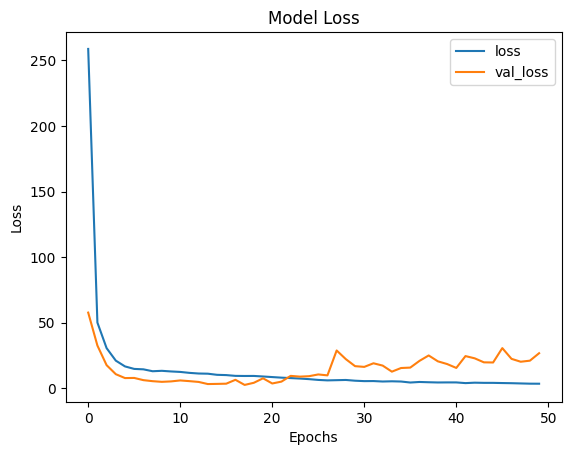

In [15]:
model.eval()
with torch.no_grad():
    dnn_pred = model(X_valid_t).numpy().ravel()
dnn_mae = mean_absolute_error(y_valid, dnn_pred)
print(f'DNN MAE: {dnn_mae:.3f}')

plt.plot(history['loss'])
plt.plot(history['val_loss'])
plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend(['loss', 'val_loss'])
plt.show()

> **해설**
>
> - **예측 전에 `model.eval()`** — 빼먹으면 Dropout 이 켜진 채 예측해서 실행할 때마다 값이 달라집니다 (채점기가 다시 계산한 값과도 달라져 오답).
> - `torch.no_grad()` 밖에서 예측하면 결과 텐서에 기울기 정보가 붙어 `.numpy()` 가 에러를 냅니다 → 그때는 `.detach().numpy()`.
> - 출력 모양 `(N, 1)` → `.ravel()` 로 `(N,)`.
> - 스케일링을 하지 않아서 DNN 이 랜덤포레스트보다 오차가 큽니다. `StandardScaler` 를 쓰면 좋아집니다 (모의고사 2에서 연습).

---
## 🏁 채점
아래 셀을 실행하면 문항별 결과와 총점이 나옵니다. 틀린 문항은 → 뒤의 이유를 읽고 고쳐 본 뒤 다시 채점해 보세요.

In [16]:
import aice_check
aice_check.grade_exam1(globals())

📋 모의고사 1 · 배달 도착시간 예측 (회귀) 채점 결과
────────────────────────────────────────────────────────────────
✅  1번 [ 4/ 4점] pandas → pd, numpy → np 로 import
✅  2번 [ 4/ 4점] seaborn → sns, matplotlib.pyplot → plt 로 import
✅  3번 [ 7/ 7점] json/csv 읽기 → df_orders, df_riders / rider_id 기준 inner merge → df
✅  4번 [ 7/ 7점] Region 이 '-' 인 행 제거 → df
✅  5번 [ 6/ 6점] jointplot(Distance_km vs Delivery_Time) → g
✅  6번 [ 7/ 7점] Speed_Per_Hour 150 이상 이상치 제거 → df_temp
✅  7번 [ 7/ 7점] 결측치가 있는 행 삭제 → df_na
✅  8번 [ 7/ 7점] order_id, rider_id, Order_Time, Arrive_Time 컬럼 삭제 → df_del
✅  9번 [ 8/ 8점] object 컬럼 전부 원-핫 인코딩 → df_preset
✅ 10번 [ 8/ 8점] X/y 분리 후 train_test_split(test_size=0.2, random_state=42)
✅ 11번 [ 8/ 8점] DecisionTreeRegressor → dt, RandomForestRegressor → rf 학습
✅ 12번 [ 8/ 8점] 검증 데이터 MAE → dt_mae, rf_mae / RMSE → rf_rmse
✅ 13번 [10/10점] PyTorch 회귀 DNN 학습 → 텐서, train_loader, model, loss_fn, optimizer, history
✅ 14번 [ 9/ 9점] eval 모드 예측 → dnn_pred, 검증 MAE → dnn_mae (+ loss 그래프)
─────────────────────────────────────

100